# T4F Performance — portfólio analítico

Tour4Friends, Projeto Integrador V e Metodologias para Projetos de Big Data Analytics, Fatec Ipiranga. Dados sintéticos; nenhum resultado representa desempenho real. Pergunta: como integrar demanda, capacidade, experiência e contribuição para apoiar decisões?

## Origem, contratos e reprodução

Snapshot público da main integrada 0216dce; seed 42. Referência 07/11/2026, histórico completo jan/2024–out/2026. O gerador original é reexecutável; hashes em docs/fontes.json. Executar npm ci, instalar requirements.txt e rodar python -m src.executar. A validação Zod original verifica schemas, chaves, vínculos, datas e pagamentos; nenhum dado faltante é imputado silenciosamente.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from src.resultados import carregar_resultados, insights
from src.ingestao import verificar_fontes
from src.executar import validar_resultado
fontes = verificar_fontes()
dados = carregar_resultados()
validar_resultado(dados)
assert fontes["dataset"]["sha256"] == dados["datasetSha256"]
display(pd.DataFrame([dados["counts"]]))

,routes,customers,departures,bookings,leads,partners,allocations,costs,payments,feedback
0,6,116,52,164,258,12,609,156,147,72


## Demanda: distribuição e calendário

Participações confirmadas por mês de início da viagem, incluindo zeros conhecidos. Uma pessoa pode viajar mais de uma vez. Dois ou três anos por mês não provam sazonalidade. Negociar capacidade antes dos picos observados, sujeito a validação em novos períodos.

,month,travelers
0,2024-01,0
1,2024-02,4
2,2024-03,3
3,2024-04,4
4,2024-05,10
5,2024-06,12
6,2024-07,5
7,2024-08,2
8,2024-09,6
9,2024-10,12


,month,n,mean,median,q1,q3,min,max,sd
0,1,3,0.000000,0.0,0.00,0.00,0,0,0.000000
1,2,3,1.333333,0.0,0.00,2.00,0,4,2.309401
2,3,3,5.333333,5.0,4.00,6.50,3,8,2.516611
3,4,3,6.333333,7.0,5.50,7.50,4,8,2.081666
4,5,3,8.333333,8.0,7.50,9.00,7,10,1.527525
5,6,3,10.666667,12.0,10.00,12.00,8,12,2.309401
6,7,3,7.000000,5.0,4.50,8.50,4,12,4.358899
7,8,3,5.333333,5.0,3.50,7.00,2,9,3.511885
8,9,3,8.000000,7.0,6.50,9.00,6,11,2.645751
9,10,3,8.000000,7.0,6.00,9.50,5,12,3.605551


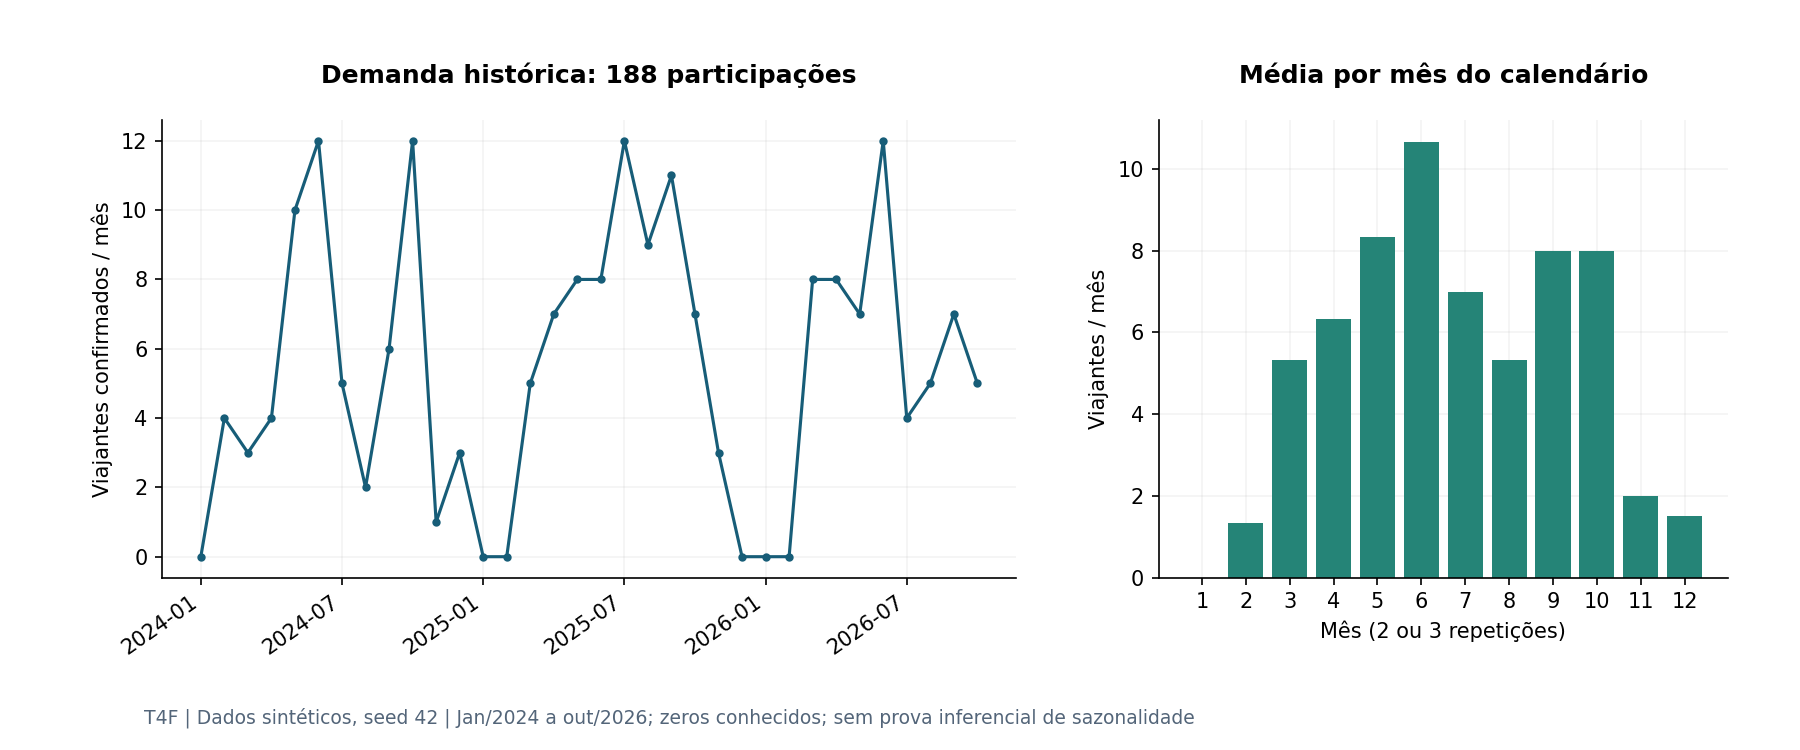

In [2]:
display(pd.DataFrame(dados["forecast"]["history"]))
display(pd.DataFrame(dados["seasonality"]["months"]))
display(Image(filename=str(RAIZ / "visualizacoes/demanda_sazonalidade.png")))

## Cancelamentos e conversão

Canceladas / todas as reservas da mesma coorte de viagem. Intervalos Wilson de referência binomial; clientes podem repetir, e rankings não demonstram diferenças. Conversão usa leads da coorte de primeiro contato com vínculo confirmado, uma população distinta. Comparar denominadores antes de decidir ações comerciais.

,dimension,name,n,cancelled,rate,lower,upper,lowSample
0,Roteiro,Português,65,6,9.230769,4.299509,18.712001,False
1,Roteiro,Português de bike,15,2,13.333333,3.736126,37.881983,False
2,Roteiro,Assis,14,3,21.428571,7.571387,47.589231,False
3,Roteiro,Santiago a pé,21,2,9.523810,2.651877,28.914139,False
4,Roteiro,Francês de bike,22,3,13.636364,4.749004,33.334987,False
5,Roteiro,Espanha cultural,7,0,0.000000,0.000000,35.433044,True
6,Canal,Agência parceira,42,3,7.142857,2.459041,19.009427,False
7,Canal,Indicação,39,3,7.692308,2.650740,20.321071,False
8,Canal,Instagram,31,4,12.903226,5.134284,28.852406,False
9,Canal,Site,32,6,18.750000,8.889545,35.309155,False


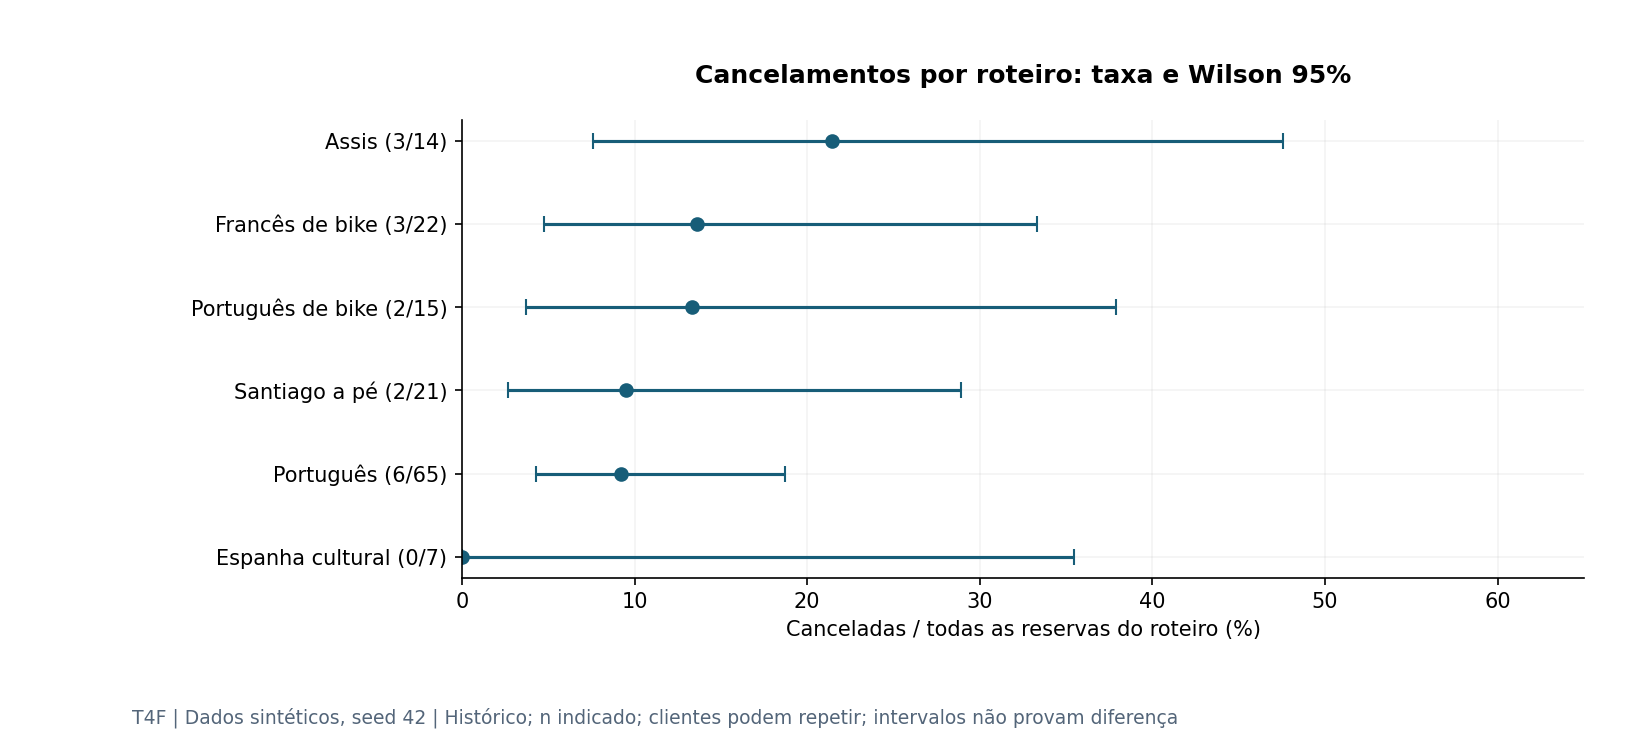

In [3]:
display(pd.DataFrame(dados["cancellations"]["groups"]))
display(Image(filename=str(RAIZ / "visualizacoes/cancelamentos.png")))

## NPS e satisfação

NPS em pontos = 100 × (promotores 9–10 − detratores 0–6) / respostas. Notas de hospedagem/atendimento/logística são dimensões distintas. Bootstrap original agrupa por cliente, 500 reamostragens, mínimo de 12 respostas e oito clientes; faixa exploratória não corrige viés de resposta.

,dimension,name,n,nps,lowSample,scores.n,scores.mean,scores.median,scores.q1,scores.q3,...,logistics.q1,logistics.q3,logistics.min,logistics.max,logistics.sd,bootstrap.lower,bootstrap.upper,bootstrap.iterations,bootstrap.clusters,bootstrap
0,Roteiro,Santiago a pé,12,25.000000,False,12,8.083333,8.0,7.75,9.00,...,7.00,8.25,5,9,1.154701,0.000000,50.000000,500.0,12.0,NaN
1,Roteiro,Português,31,32.258065,False,31,8.225806,8.0,7.00,10.00,...,6.50,9.00,5,10,1.667527,15.106952,48.387097,500.0,28.0,NaN
2,Roteiro,Francês de bike,12,58.333333,False,12,8.583333,9.0,8.00,9.00,...,8.00,9.00,5,10,1.288057,33.333333,80.181818,500.0,10.0,NaN
3,Roteiro,Português de bike,7,85.714286,True,7,8.857143,9.0,9.00,9.00,...,8.00,8.50,6,10,1.214986,NaN,NaN,NaN,NaN,NaN
4,Roteiro,Espanha cultural,6,50.000000,True,6,8.500000,8.5,7.25,9.75,...,7.25,9.75,7,10,1.378405,NaN,NaN,NaN,NaN,NaN
5,Roteiro,Assis,4,50.000000,True,4,8.500000,8.5,7.00,10.00,...,6.75,10.00,6,10,2.061553,NaN,NaN,NaN,NaN,NaN
6,Categoria,Alternativa,14,42.857143,False,14,8.500000,8.5,7.25,10.00,...,7.00,9.75,5,10,1.540658,25.000000,61.538462,500.0,13.0,NaN
7,Categoria,Premium,39,48.717949,False,39,8.461538,9.0,8.00,9.00,...,7.00,9.00,5,10,1.347262,35.714286,61.575092,500.0,33.0,NaN
8,Categoria,Conforto,19,31.578947,False,19,8.052632,8.0,7.00,9.50,...,6.50,9.50,5,10,1.668420,10.526316,47.894737,500.0,19.0,NaN


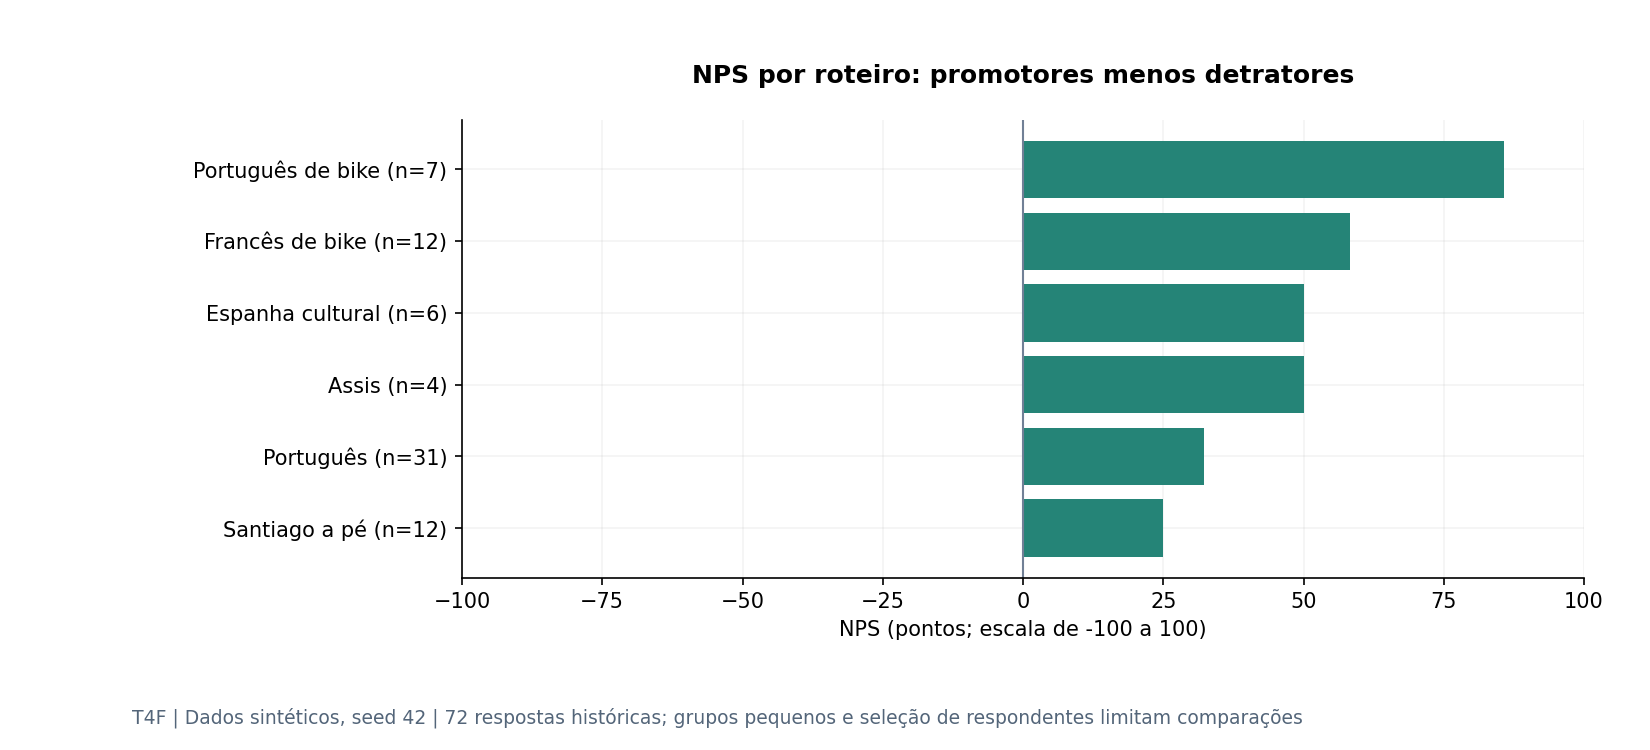

In [4]:
display(pd.json_normalize(dados["satisfaction"]["groups"]))
display(Image(filename=str(RAIZ / "visualizacoes/satisfacao_nps.png")))

## Capacidade: agregação não elimina gargalos

Planejamento global de 07/11 a 31/12/2026. Comprometimento vem das participações confirmadas por saída/categoria em cada slot de data/etapa. Vagas-noite não são viajantes/mês nem quantidade de hotéis. Déficit é somado após max(0, comprometimento − capacidade) por slot.

,routeName,date,category,capacity,committed,shortage
0,Português,2026-11-10,Premium,5,3,0
1,Português,2026-11-10,Conforto,4,2,0
2,Português,2026-11-10,Alternativa,6,2,0
3,Português,2026-11-11,Premium,2,3,1
4,Português,2026-11-11,Conforto,5,2,0
5,Português,2026-11-11,Alternativa,5,2,0
6,Português,2026-11-12,Premium,6,3,0
7,Português,2026-11-12,Conforto,5,2,0
8,Português,2026-11-12,Alternativa,4,2,0
9,Português,2026-11-13,Premium,6,3,0


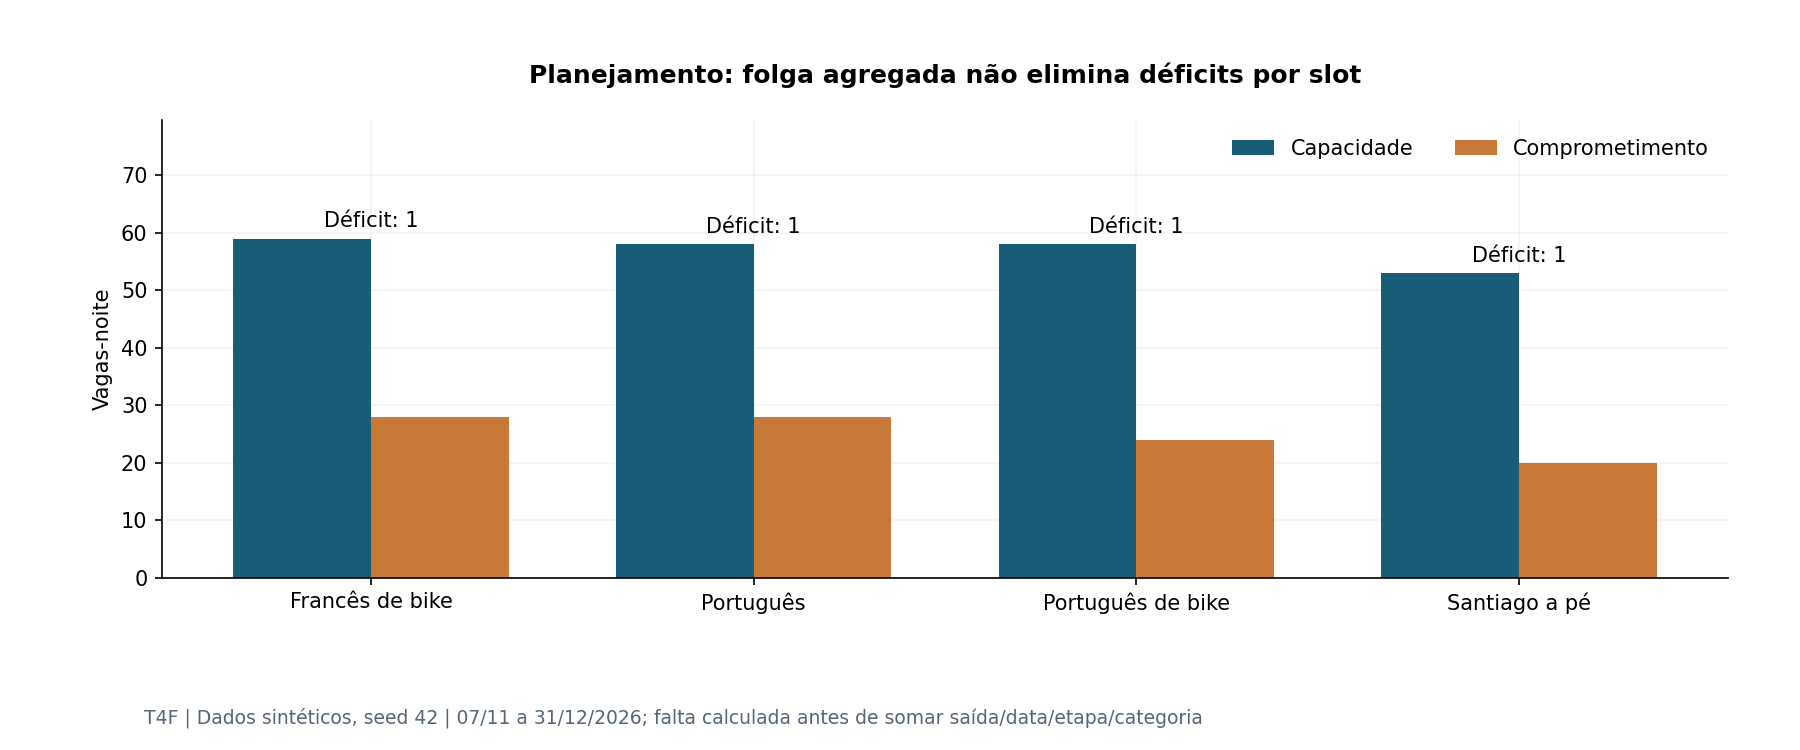

In [5]:
display(pd.DataFrame(dados["planning"]["slots"])[["routeName", "date", "category", "capacity", "committed", "shortage"]])
display(Image(filename=str(RAIZ / "visualizacoes/ocupacao_planejamento.png")))

## Receita, custos e contribuição

Total da reserva conta uma vez; participantes não multiplicam a receita. Contribuição é receita contratada menos custos da coorte de saídas. Não é lucro líquido. Não somar receita a recebimentos. O cenário contém Assis e Espanha cultural além de Caminhos de Santiago; os registros não foram rebatizados.

,shortName,travelers,revenue,cost,contribution,margin
0,Português,87,714400,516108,198292,27.756439
1,Santiago a pé,32,289200,201213,87987,30.424274
2,Francês de bike,27,249700,170393,79307,31.760913
3,Português de bike,17,144700,108703,35997,24.876987
4,Assis,14,125100,90019,35081,28.042366
5,Espanha cultural,11,95500,74746,20754,21.731937


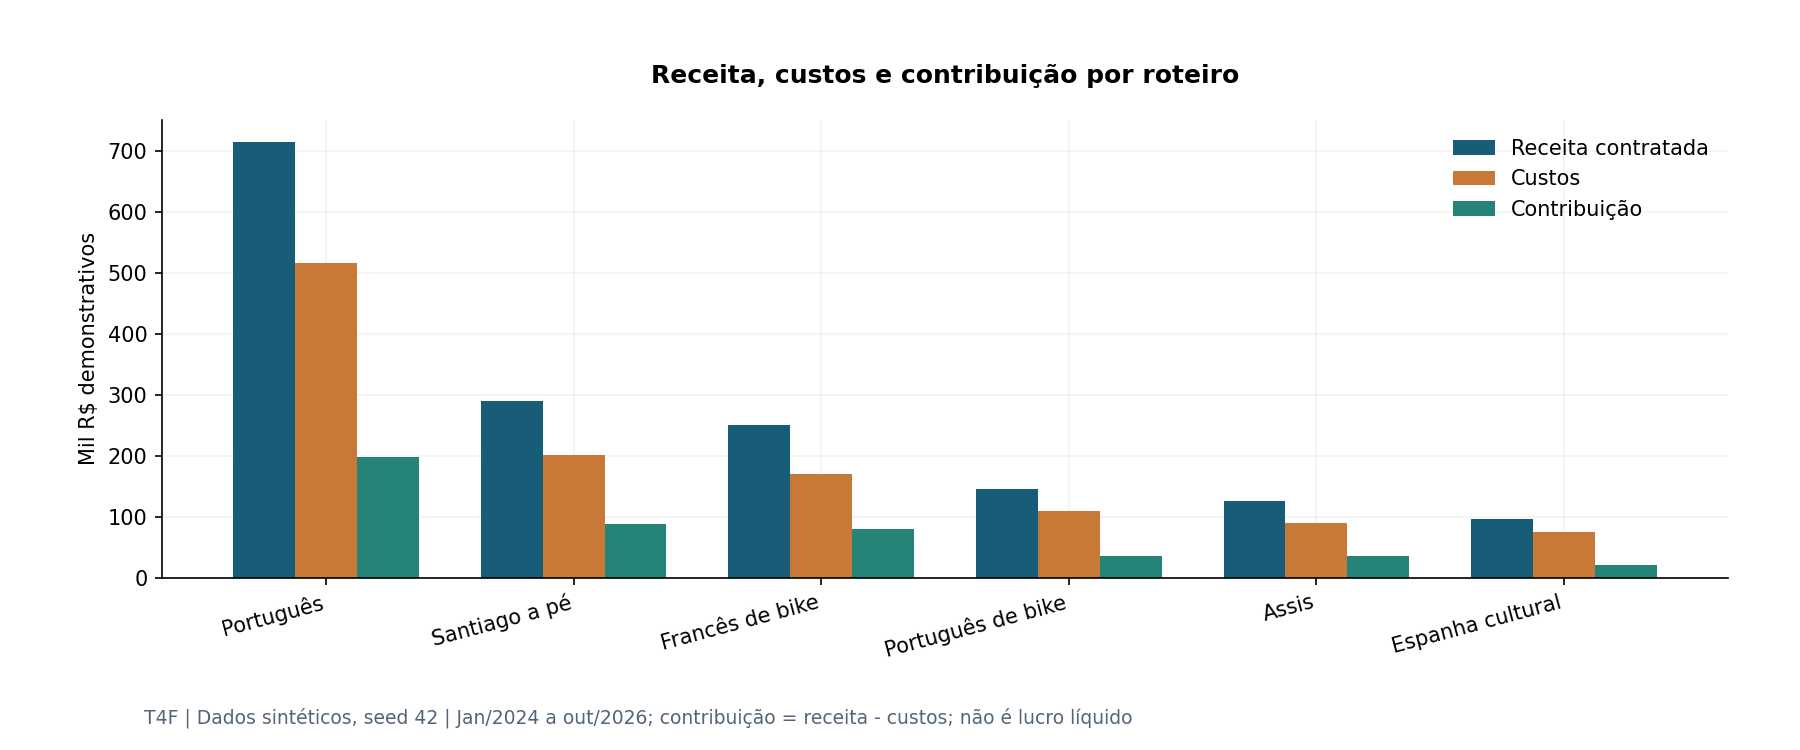

In [6]:
display(pd.DataFrame(dados["historical"]["routes"])[["shortName", "travelers", "revenue", "cost", "contribution", "margin"]])
display(Image(filename=str(RAIZ / "visualizacoes/financeiro_roteiros.png")))

## Previsão e avaliação temporal

Reuso integral do motor original: sazonal ingênuo, média ponderada, tendência amortecida e Ridge λ=4. Seleção H=3 em origens expansivas de jan/2024–abr/2026; holdout de mai–out/2026 separado. Futuro confirmado não entra no treino. Média ponderada venceu no teste final, sem reseleção. Faixas são exploratórias, sem garantia nominal; não há reconciliação hierárquica.

,model,modelId,horizon,windows,mae,rmse,bias,wape,count
0,Sazonal ingênuo,seasonal,1,16,3.000000,3.708099,-0.750000,55.813953,16
1,Média ponderada,weighted,1,16,3.343750,3.924416,-0.406250,62.209302,16
2,Tendência amortecida,damped,1,16,3.887417,4.401698,-0.317619,72.324032,16
3,Ridge temporal,ridge,1,16,2.305935,2.787262,-0.276119,42.901122,16
4,Sazonal ingênuo,seasonal,3,14,3.214286,3.882194,-0.833333,57.692308,42
5,Média ponderada,weighted,3,14,4.321098,5.001434,-0.227183,77.558167,42
6,Tendência amortecida,damped,3,14,4.928738,5.617946,-0.033837,88.464523,42
7,Ridge temporal,ridge,3,14,2.581704,3.126524,-0.401997,46.338285,42
8,Sazonal ingênuo,seasonal,6,11,3.606061,4.213974,-0.969697,58.476658,66
9,Média ponderada,weighted,6,11,5.322487,6.213802,-0.020404,86.310600,66


,model,modelId,horizon,windows,mae,rmse,bias,wape,count
0,Sazonal ingênuo,seasonal,6,1,3.833333,4.415880,2.500000,57.500000,6
1,Média ponderada,weighted,6,1,2.133488,2.640938,0.466821,32.002315,6
2,Tendência amortecida,damped,6,1,2.136559,2.920857,-0.974392,32.048388,6
3,Ridge temporal,ridge,6,1,2.556670,2.750766,1.377065,38.350050,6


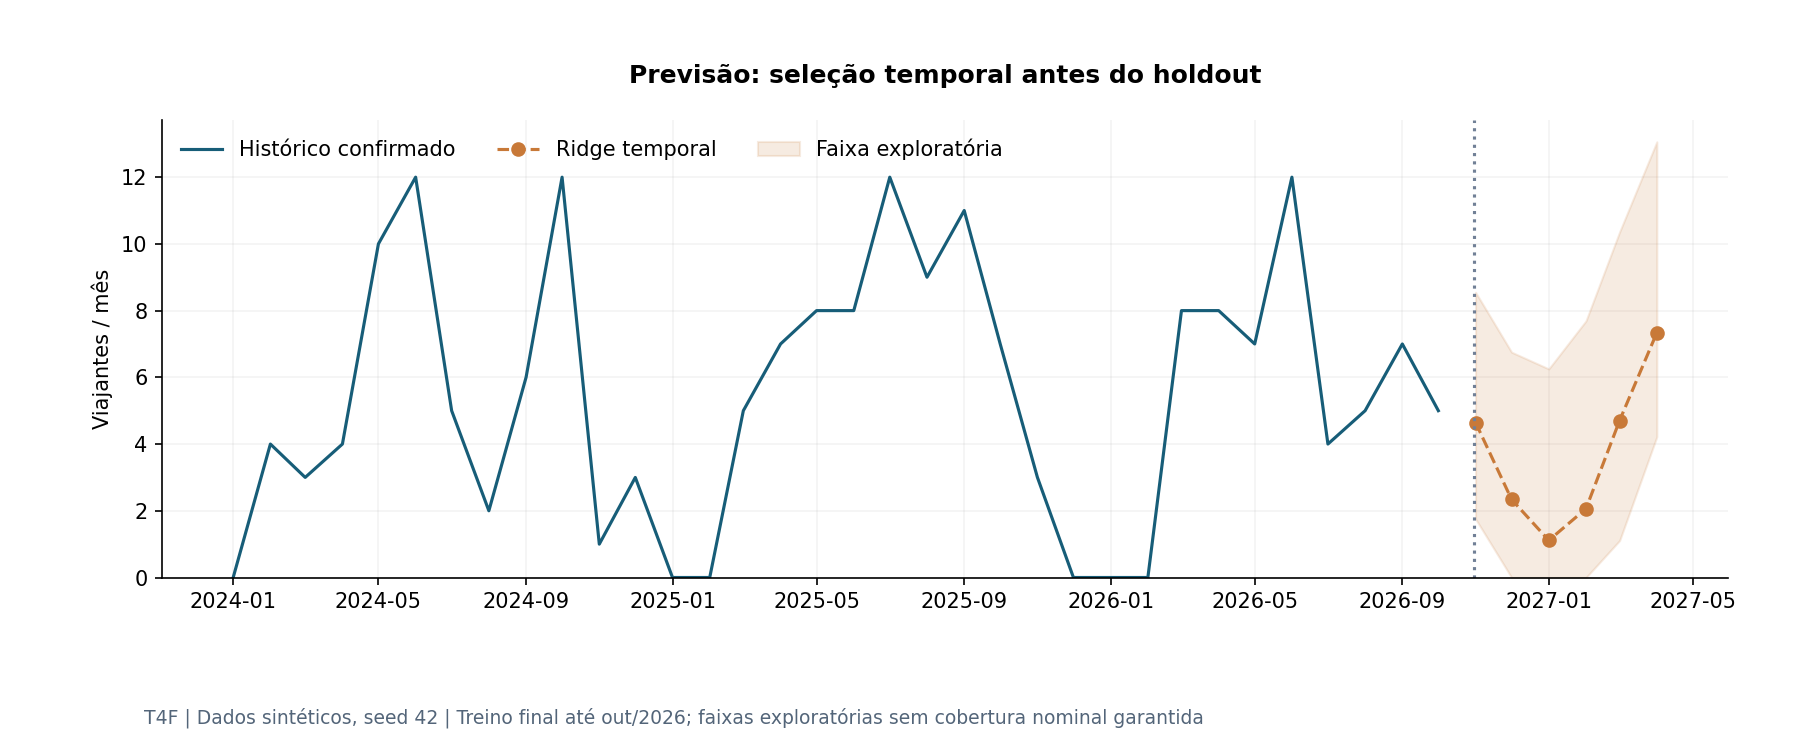

In [7]:
display(pd.DataFrame(dados["forecast"]["validation"]))
display(pd.DataFrame(dados["forecast"]["metrics"]))
display(Image(filename=str(RAIZ / "visualizacoes/previsao_demanda.png")))

## Decisões, metodologias e limites

CRISP-DM: problema → dados → preparação → análise/modelos → avaliação → entrega local. KDD: seleção do snapshot → validação → tabelas → descoberta exploratória → interpretação. Panorama e Canvas organizam problema e valor; planejamento e DataOps têm evidências em hashes, validações e artefatos. O documento acadêmico recebido descreve Scrum e contém quadro Kanban; isso não comprova a execução de todas as sprints. Ver docs/metodologias.md e docs/leitura-documentacao.md para o cotejo por página.

In [8]:
for texto in insights(dados):
    display(Markdown(texto))

O mês 6 tem a maior média observada (10,7 viajantes; n=3), ante 0 no mês 1. Compare disponibilidade antes de ampliar vendas; são apenas 3 repetições do mês, sem comprovação inferencial de sazonalidade.

Assis apresenta a maior taxa observada entre roteiros com ao menos dez reservas: 21,4% (3/14), Wilson 95% 7,6–47,6%. Investigue motivos e canais; ranking descritivo não comprova diferença entre grupos.

Santiago a pé tem o menor NPS observado entre roteiros com 12 respostas: 25 (n=12). Hospedagem 7,1, atendimento 8,9 e logística 7,7 em dez pontos. Revise comentários; seleção de respondentes e amostra pequena impedem concluir causalidade ou diferença robusta.

Planejamento de 07/11 a 31/12/2026: ocupação de 43,86% (100/228 vagas-noite), com déficit de 4 vagas-noite em slots específicos. Negociar por saída/data/etapa/categoria; folga em outro slot não cobre a falta.

No histórico, receita contratada de R$ 1.618.600,00, custos de R$ 1.161.182,00 e contribuição de R$ 457.418,00. Não é lucro líquido: tributos, estornos e conciliação contábil não foram modelados.

Ridge temporal selecionado antes do teste final. MAE no holdout: 2,5567 viajantes/mês; RMSE 2,7508. A média ponderada teve menor MAE final; não se escolheu novamente o modelo após observar o teste.

## Base acadêmica complementar recebida

O ZIP anexado é outra simulação, seed 2026: reservas em EUR e categorias Econômico/Standard/Superior. Não unir à demo seed 42 em BRL, Premium/Conforto/Alternativa. Ocupação e financeiro são independentes de reservas. NPS 72 foi imposto no gerador. As tabelas com prefixo real_ têm origem secundária ou calendário calculado, sem certificação primária nesta entrega.

In [9]:
import json
suplementar = json.loads((RAIZ / "data/processed/analise-suplementar.json").read_text(encoding="utf-8"))
display(pd.DataFrame([suplementar["contagens"]]))
display(pd.DataFrame([{chave: suplementar[chave] for chave in ("nps_total", "respostas_total", "nps_ate_referencia", "respostas_ate_referencia", "respostas_futuras")}]))
display(pd.DataFrame([suplementar["portomarin"]]))
assert suplementar["portomarin"]["taxa_pct"] == 150
assert suplementar["respostas_futuras"] == 7

,real_clima_santiago_normais_1991_2020,real_feriados_2026_2027,real_oficina_peregrino_2025_brasil_por_caminho,real_oficina_peregrino_2025_mensal,sintetico_clientes,sintetico_feedbacks_nps,sintetico_financeiro_mensal,sintetico_ocupacao_hospedagens,sintetico_reservas
0,12,76,7,12,422,300,7,4662,469


,nps_total,respostas_total,nps_ate_referencia,respostas_ate_referencia,respostas_futuras
0,72.0,300,72.696246,293,7


,data,categoria,capacidade,comprometidas,taxa_pct
0,2026-11-14,Superior,2,3,150.0


## Próximos passos

Validar indicadores com novos períodos e dados operacionais autorizados; conferir as fontes externas primárias antes de uso comercial. O relatório acadêmico foi incluído como referência documental, com matrículas ocultadas e divergências técnicas explicitadas. Este portfólio é publicado no GitHub; Streamlit permanece uma execução local. Fonte: https://github.com/Thiago-code-lab/Dashboards-Tour4Friends/tree/0216dce5f67b83fbb0ba84346a7742dcb4f5ce23 .